# Identifying main contributing factors to NBA Draft Selection of college players

**Requirements**

In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

In [341]:
# to be able to review all rows/columns of the data when desired:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

In [342]:
# hiding warnings
import warnings
warnings.filterwarnings('ignore')

**Data Import**

In [ ]:
# general path setup:


In [347]:
import os

# Simpler path setup: assume datasets are stored in a 'data' directory in your repository
DATA_PATH = os.getcwd()

print(f"Data directory is set to: {DATA_PATH}")
print("To use this notebook, make sure your download and store the dataset CSV files inside this folder.")

Data directory is set to: /content
To use this notebook, make sure your download and store the dataset CSV files inside this folder.


In [348]:
# College statistics 13 years between 2009-2022 loaded from the repository's data directory
college_stats_df1 = pd.read_csv(os.path.join(DATA_PATH, 'CollegeBasketballPlayers2009-2021.csv'), low_memory=False)
college_stats_df2 = pd.read_csv(os.path.join(DATA_PATH, 'CollegeBasketballPlayers2022.csv'))

In [349]:
# NBA draft combine loaded from the repository's data directory
draft_df = pd.read_csv(os.path.join(DATA_PATH, 'draft_combine_stats.csv'))

**Data clean-up/merge**

In [283]:
# merge years 2009-2021 with year 2022
college_stats_df = pd.concat([college_stats_df1, college_stats_df2])
college_stats_df.shape

(65039, 66)

In [211]:
college_stats_df.sort_values(by=['player_name', 'year'], inplace=True, ignore_index=True)

In [350]:
# counting years in college for 'experience'
player_total_years = college_stats_df.groupby(['player_name','pid']).agg({'year':'nunique',}).reset_index().values

for i,j,y_cnt in player_total_years:
  college_stats_df.loc[(college_stats_df['player_name'] == i) & (college_stats_df['pid'] == j), 'total_yrs'] = y_cnt


In [286]:
# drop one unnamed column and rename another unnamed to 'position':
college_stats_df.drop(columns=['Unnamed: 65'], inplace=True)
college_stats_df.rename(columns={'Unnamed: 64':'position'}, inplace=True)

# encode college year into numeric, rename:
college_yr = dict({'Fr':1,'So':2,'Jr':3,'Sr':4})
college_stats_df['yr'] = college_stats_df['yr'].map(college_yr)
# rename yr column to college_year:
college_stats_df.rename(columns={'yr':'college_year'}, inplace=True)


,player_name,team,conf,GP,Min_per,Ortg,usg,eFG,TS_per,ORB_per,DRB_per,AST_per,TO_per,FTM,FTA,FT_per,twoPM,twoPA,twoP_per,TPM,TPA,TP_per,blk_per,stl_per,ftr,college_year,ht,num,porpag,adjoe,pfr,year,pid,type,Rec Rank,ast/tov,rimmade,rimmade+rimmiss,midmade,midmade+midmiss,rimmade/(rimmade+rimmiss),midmade/(midmade+midmiss),dunksmade,dunksmiss+dunksmade,dunksmade/(dunksmade+dunksmiss),pick,drtg,adrtg,dporpag,stops,bpm,obpm,dbpm,gbpm,mp,ogbpm,dgbpm,oreb,dreb,treb,ast,stl,blk,pts,position,total_yrs
3973,Aquan Smart,FIU,CUSA,21,11.7,69.4,17.7,32.1,36.08,1.8,12.2,10.5,22.3,7,14,0.500,6,18,0.333,2,10,0.200,2.6,0.0,50.0,2.0,3-Jun,23.0,-0.298101,72.3696,5.7,2022,74925,all,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
3974,Chase Barrs,Florida A&M,SWAC,14,11.0,85.1,8.8,42.9,40.61,5.4,8.7,8.1,22.7,2,6,0.333,3,7,0.429,0,0,0.000,2.4,1.3,85.7,3.0,9-Jun,1.0,-0.317084,70.7183,3.6,2022,75001,all,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
3975,Hugo Clarkin,Sacramento St.,BSky,16,22.8,99.7,7.8,70.6,68.67,2.9,13.9,5.9,33.1,0,1,0.000,12,15,0.800,0,2,0.000,4.0,1.3,5.9,2.0,Jul-00,5.0,-0.029577,84.4675,6.2,2022,75094,all,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
3976,James Graham III,Maryland,B10,7,1.8,9.4,17.1,0.0,0.00,0.0,30.9,7.6,32.6,0,0,0.000,0,0,0.000,0,5,0.000,0.0,0.0,0.0,2.0,8-Jun,1.0,-0.826427,9.4765,1.8,2022,75420,all,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
3977,Zane Butler,SIU Edwardsville,OVC,12,7.0,84.8,10.6,35.0,41.10,5.2,10.0,7.8,23.3,2,2,1.000,2,4,0.500,1,6,0.167,0.0,3.3,20.0,2.0,NaN,NaN,-0.283049,71.2723,2.9,2022,75421,all,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0


In [352]:
# clean-up player_names by removing '.' that occasionally occurs in the first name, in order to merge tables on the names and years
college_stats_df['player_name'] = college_stats_df['player_name'].str.replace('.','')
# and also any special characters like ' or ?, keep only alpha-characters:
college_stats_df['player_name'] = college_stats_df['player_name'].str.replace('[^a-zA-Z ]', '', regex=True)

In [353]:
# same for draft combine table
draft_df['player_name'] = draft_df['player_name'].str.replace('.','')
draft_df['player_name'] = draft_df['player_name'].str.replace('[^a-zA-Z ]', '', regex=True)

In [356]:
# drop years 2001-2008 and 2023 from draft_df, to have same years as the college data
draft_df = draft_df[draft_df['season'] != 2023]
draft_df = draft_df[draft_df['season'] != 2016]
draft_df = draft_df[draft_df['season'] >= 2009]


In [357]:
# additional cleanup to avoid uncertain name duplicates that can't be resolved/uniquely mapped.
# In draft_df remove rows with names that occur several times with different player_id and empty player id, # even when it's a different season.
# first fill in missing player_id with a dummy: 99999
draft_df['player_id'] = draft_df['player_id'].fillna(int(99999))

#  remove rows with player id 99999 if this name already exists in a different row with a different (non-empty) id:
for n,p in draft_df[['player_name','player_id']].values:
  if (draft_df[(draft_df['player_name'] == n) & (draft_df['player_id'] == 99999)].shape[0] >= 1) & (draft_df[(draft_df['player_name'] == n) & (draft_df['player_id'] != 99999)].shape[0] >= 1):
    draft_df.drop(draft_df[(draft_df['player_name'] == n) & (draft_df['player_id'] == 99999)].index, inplace=True)

In [358]:
draft_df.shape

(728, 47)

In [359]:
# clean-up repeated draft combine appearances by player_name and player_id in draft_df -> keep only the latest year:
draft_df.sort_values(by=['player_name','player_id','season'], inplace=True, ignore_index=True)
draft_df = draft_df.loc[draft_df.groupby(['player_name','player_id'])['season'].idxmax()]
# this automatically removes the player_id with NaN
# reset index in reduced college_stats_df:
draft_df.reset_index(drop=True, inplace=True)


In [296]:
draft_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 714 entries, 0 to 713
Data columns (total 47 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   season                        714 non-null    int64  
 1   player_id                     714 non-null    int64  
 2   first_name                    714 non-null    object 
 3   last_name                     714 non-null    object 
 4   player_name                   714 non-null    object 
 5   position                      712 non-null    object 
 6   height_wo_shoes               684 non-null    float64
 7   height_wo_shoes_ft_in         684 non-null    object 
 8   height_w_shoes                684 non-null    float64
 9   height_w_shoes_ft_in          684 non-null    object 
 10  weight                        683 non-null    float64
 11  wingspan                      685 non-null    float64
 12  wingspan_ft_in                685 non-null    object 
 13  stand

In [360]:
# merge college_stats_df which includes draft positions where applicable and draft_df from the combine, by player_name, year/season to one bog table
data_df = college_stats_df.merge(draft_df, left_on=['player_name','year'], right_on=['player_name','season'], how='left')
data_df.shape

(65039, 112)

In [361]:
# show data_df values only for rows where draft_df had corresponding player_names and season, i.e. non NaN in data_df:
data_df[data_df['season'].notna()].shape

(623, 112)

In [362]:
# now for each player_name, pid pair keep only the row with his most recent 'year':
data_df = data_df.loc[data_df.groupby(['player_name','pid'])['year'].idxmax()]
data_df.shape

(26449, 112)

In [363]:
# Creating additional categorical versions for the draft picks. Will allow to group with larger sample sizes

# Binary: if drafted = 1, else 0:
data_df['drafted'] = np.where(data_df['pick'].notna(), 1, 0)

# Categorical assignment as lottery round 1, non-lottery round 1, round 2, undrafted:
data_df['draft_round'] = data_df['pick'].apply(lambda x: 'Lottery_Round_1' if x <= 14 else ('Non-Lottery_Round_1' if x <= 30 else ('Undrafted' if np.isnan(x) else 'Round_2')))

In [365]:
# Defining intuitive order to the draft categories
draft_categories_order = ['Undrafted', 'Round_2', 'Non-Lottery_Round_1', 'Lottery_Round_1']

# Convert 'draft_round' to an ordered Categorical variable
data_df['draft_round'] = pd.Categorical(
    data_df['draft_round'],
    categories=draft_categories_order,
    ordered=True
)

**Analysis of various feature importantce (Correlations, t-tests, ANOVA)**

**1. Physical Attributes (H1)**
- Research Question: Are physical measurements (height, wingspan, weight, vertical leap) and athleticism associated with a higher draft position?
- Hypothesis: Taller players with wider wingspans and higher vertical leaps are drafted earlier.

=== 1. Correlation of Physical Attributes with Draft Pick (1-60) ===
height_wo_shoes              -0.153694
wingspan                     -0.143346
weight                       -0.131763
standing_vertical_leap       -0.041990
max_vertical_leap            -0.037078
body_fat_pct                 -0.002213
hand_length                  -0.107973
hand_width                   -0.071563
lane_agility_time             0.072469
modified_lane_agility_time    0.034346
three_quarter_sprint          0.114757
bench_press                  -0.034863
Name: pick, dtype: float64


=== 1. Most Correlated Physical Attributes - Scatter plors with Draft Picks (1-60) ===


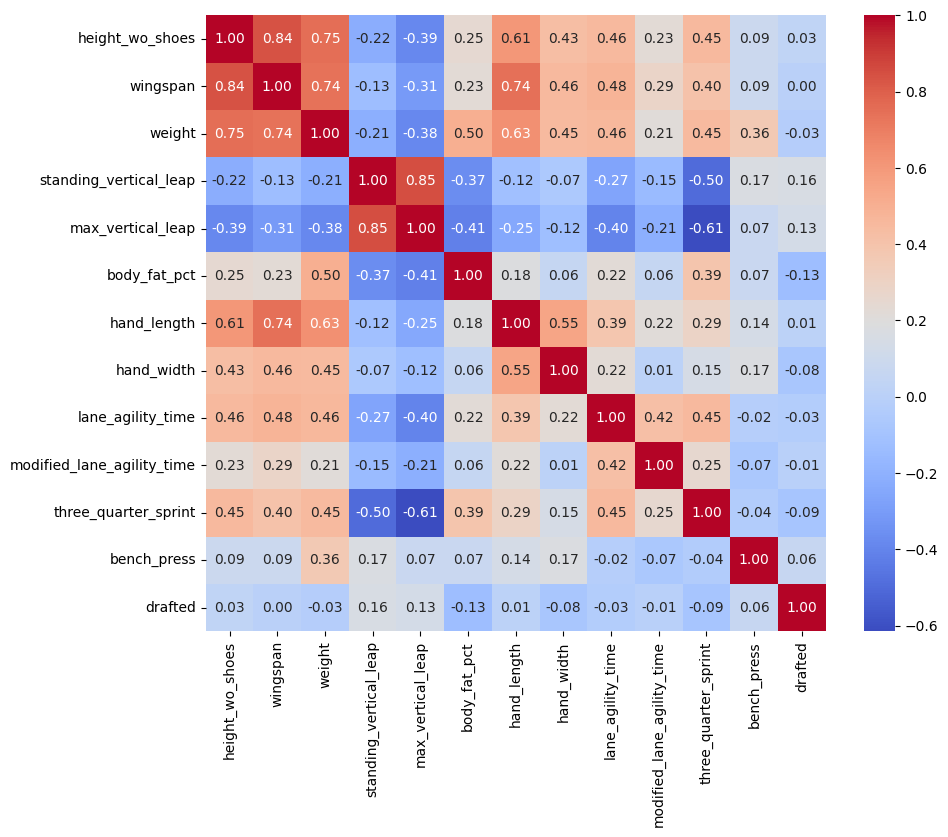

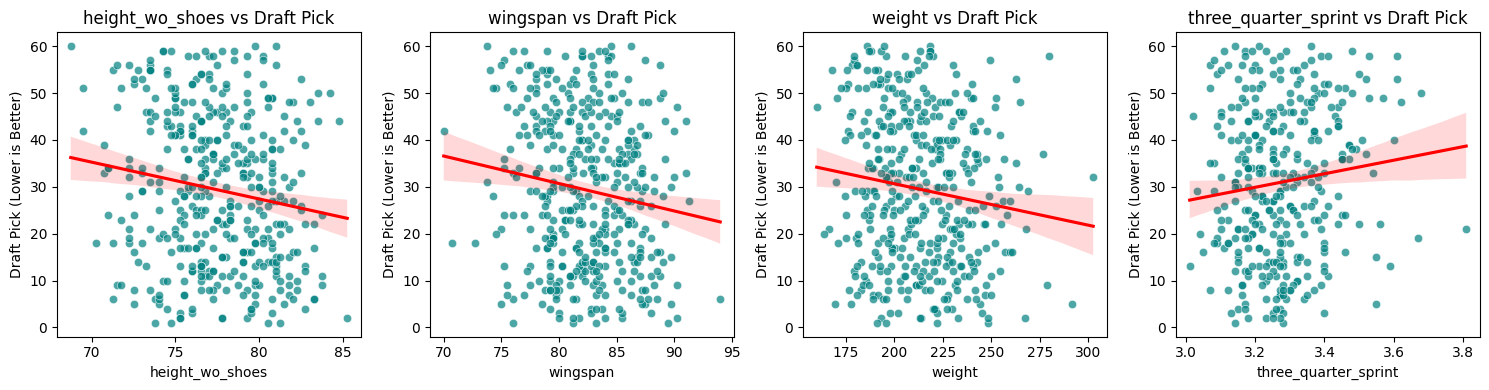

In [371]:
# ---------------------------------------------------
# 1. HYPOTHESIS 1: Physical Attributes & Draft Status
#
# Filter for drafted players to check correlation with draft pick position
drafted_players = data_df[data_df['drafted'] == 1].copy()

# Convert columns to numeric if not already
physical_cols = ['height_wo_shoes', 'wingspan', 'weight', 'standing_vertical_leap', 'max_vertical_leap','body_fat_pct','hand_length','hand_width','lane_agility_time','modified_lane_agility_time','three_quarter_sprint','bench_press']
for col in physical_cols:
    drafted_players[col] = pd.to_numeric(drafted_players[col], errors='coerce')
    data_df[col] = pd.to_numeric(data_df[col], errors='coerce')

print("=== 1. Correlation of Physical Attributes with Draft Pick (1-60) ===")
physical_corr_df = drafted_players[physical_cols + ['pick']].corr()[['pick']].drop('pick')
print(physical_corr_df['pick'])
print("\n")

# another plot with correlation matrix, as heatmap
corr_matrix = data_df[physical_cols + ['drafted']].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")

# Visualize physical attributes vs. Draft Position
print("=== 1. Most Correlated Physical Attributes - Scatter plors with Draft Picks (1-60) ===")
plt.figure(figsize=(15, 4))
for i, col in enumerate(physical_corr_df['pick'].abs().sort_values(ascending=False).head(4).index, 1):
    plt.subplot(1, 4, i)
    sns.scatterplot(data=drafted_players, x=col, y='pick', alpha=0.7, color='teal')
    sns.regplot(data=drafted_players, x=col, y='pick', scatter=False, color='red')
    plt.title(f'{col} vs Draft Pick')
    plt.ylabel('Draft Pick (Lower is Better)')
plt.tight_layout()
plt.show()




**2. College Performance (H2)**
- Research Question: Which statistical metrics (points, rebounds, assists, blocks, shooting percentages, etc.) have the strongest influence on draft positions?
- Hypothesis: Players with more dominant offensive and defensive box-score statistics are drafted earlier.

=== Average Physical Metrics by Draft Status (Drafted vs. Undrafted) ===


,height_wo_shoes,wingspan,weight,standing_vertical_leap,max_vertical_leap,body_fat_pct,hand_length,hand_width,lane_agility_time,modified_lane_agility_time,three_quarter_sprint,bench_press
drafted,,,,,,,,,,,,
0,77.220414,82.326923,215.239053,28.766892,34.523649,7.584345,8.712121,9.513636,11.301293,3.064957,3.299932,9.112360
1,77.457332,82.334173,213.778313,29.815000,35.541311,6.877807,8.724274,9.387863,11.265565,3.061538,3.275673,9.834483



=== T-tests: Drafted vs. Undrafted Physical Metrics ===
height_wo_shoes           | T-stat:   0.7691 | P-value: 4.4249e-01
wingspan                  | T-stat:   0.0191 | P-value: 9.8477e-01
weight                    | T-stat:  -0.6192 | P-value: 5.3627e-01
standing_vertical_leap    | T-stat:   3.5801 | P-value: 4.0635e-04
max_vertical_leap         | T-stat:   2.9150 | P-value: 3.8540e-03
body_fat_pct              | T-stat:  -2.9440 | P-value: 3.5270e-03
hand_length               | T-stat:   0.2601 | P-value: 7.9495e-01
hand_width                | T-stat:  -1.7902 | P-value: 7.4486e-02
lane_agility_time         | T-stat:  -0.6546 | P-value: 5.1329e-01
modified_lane_agility_time | T-stat:  -0.1201 | P-value: 9.0454e-01
three_quarter_sprint      | T-stat:  -1.8575 | P-value: 6.4368e-02
bench_press               | T-stat:   1.2366 | P-value: 2.1807e-01

=== Average Physical Metrics by Draft Round Category ===


,height_wo_shoes,wingspan,weight,standing_vertical_leap,max_vertical_leap,body_fat_pct,hand_length,hand_width,lane_agility_time,modified_lane_agility_time,three_quarter_sprint,bench_press
draft_round,,,,,,,,,,,,
Undrafted,77.220414,82.326923,215.239053,28.766892,34.523649,7.584345,8.712121,9.513636,11.301293,3.064957,3.299932,9.112360
Round_2,77.024235,81.915051,211.599490,29.823034,35.519553,6.823112,8.688187,9.344780,11.311073,3.068496,3.290056,9.958042
Non-Lottery_Round_1,77.688525,82.592213,215.294262,29.655340,35.422330,6.938099,8.747727,9.450000,11.218235,3.053929,3.261176,9.626374
Lottery_Round_1,78.035714,82.845960,216.274227,30.032609,35.775362,6.912755,8.770115,9.399425,11.216667,3.047692,3.259559,9.857143



=== ANOVA: Comparing Draft Round Groups for Physical Metrics ===
height_wo_shoes           | F-stat:   2.6333 | P-value: 4.9143e-02
wingspan                  | F-stat:   1.3998 | P-value: 2.4189e-01
weight                    | F-stat:   1.1200 | P-value: 3.4031e-01
standing_vertical_leap    | F-stat:   4.5290 | P-value: 3.8162e-03
max_vertical_leap         | F-stat:   3.0221 | P-value: 2.9379e-02
body_fat_pct              | F-stat:   3.4227 | P-value: 1.7042e-02
hand_length               | F-stat:   0.7006 | P-value: 5.5201e-01
hand_width                | F-stat:   1.6667 | P-value: 1.7314e-01
lane_agility_time         | F-stat:   1.0210 | P-value: 3.8300e-01
modified_lane_agility_time | F-stat:   0.0871 | P-value: 9.6706e-01
three_quarter_sprint      | F-stat:   2.7319 | P-value: 4.3275e-02
bench_press               | F-stat:   0.5375 | P-value: 6.5683e-01


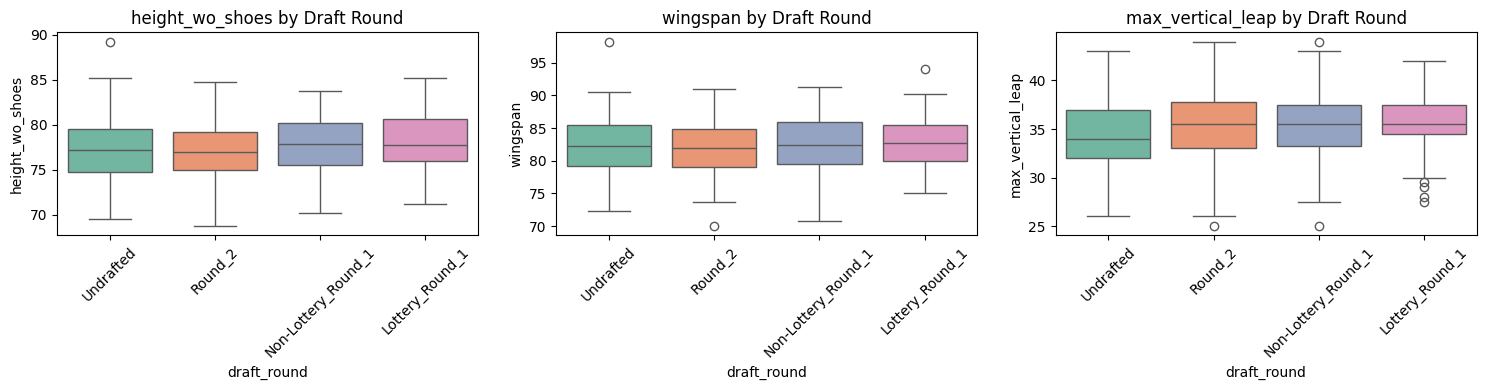

In [372]:
# ----------------------------------------------------------------
# PHYSICAL METRICS GROUPING ANALYSIS (Drafted 0/1 & Draft Rounds)
#

# 1. Compare Physical Metrics: Drafted (1) vs. Undrafted (0) players
print("=== Average Physical Metrics by Draft Status (Drafted vs. Undrafted) ===")
group_drafted = data_df.groupby('drafted')[physical_cols].mean()
display(group_drafted)

print("\n=== T-tests: Drafted vs. Undrafted Physical Metrics ===")
for col in physical_cols:
    drafted_vals = data_df[data_df['drafted'] == 1][col].dropna()
    undrafted_vals = data_df[data_df['drafted'] == 0][col].dropna()
    if len(drafted_vals) > 1 and len(undrafted_vals) > 1:
        t_stat, p_val = stats.ttest_ind(drafted_vals, undrafted_vals, equal_var=False)
        print(f"{col:25} | T-stat: {t_stat:8.4f} | P-value: {p_val:.4e}")

# 2. Compare Physical Metrics across Draft Rounds (Lottery, Non-Lottery Rd 1, Rd 2, Undrafted)
print("\n=== Average Physical Metrics by Draft Round Category ===")
group_rounds = data_df.groupby('draft_round')[physical_cols].mean()
display(group_rounds)

print("\n=== ANOVA: Comparing Draft Round Groups for Physical Metrics ===")
for col in physical_cols:
    groups = [data_df[data_df['draft_round'] == r][col].dropna() for r in data_df['draft_round'].unique()]
    groups = [g for g in groups if len(g) > 0]
    if len(groups) > 1:
        f_stat, p_val = stats.f_oneway(*groups)
        print(f"{col:25} | F-stat: {f_stat:8.4f} | P-value: {p_val:.4e}")

# Visualize physical metrics across draft rounds
plt.figure(figsize=(15, 4))
for i, col in enumerate(['height_wo_shoes', 'wingspan', 'max_vertical_leap'], 1):
    plt.subplot(1, 3, i)
    sns.boxplot(data=data_df, x='draft_round', y=col, palette='Set2')
    plt.xticks(rotation=45)
    plt.title(f'{col} by Draft Round')
plt.tight_layout()
plt.show()


=== Correlation of College Performance with Draft Pick ===
pts         -0.103062
treb        -0.095155
oreb        -0.102473
dreb        -0.077043
ast         -0.022535
stl         -0.119758
blk         -0.110878
ast/tov      0.060666
eFG         -0.139307
TS_per      -0.148571
Ortg        -0.118499
drtg         0.184789
usg         -0.104448
FT_per       0.056605
twoP_per    -0.171556
TP_per      -0.019684
Rec Rank    -0.191210
total_yrs    0.396447
Name: pick, dtype: float64




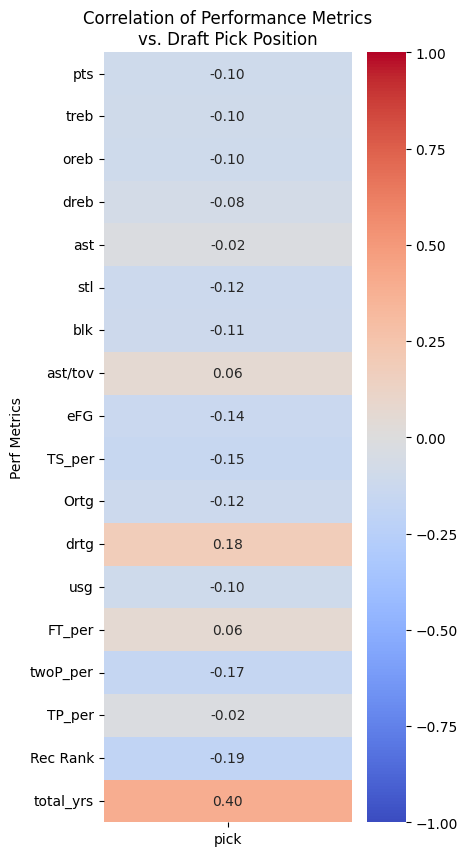

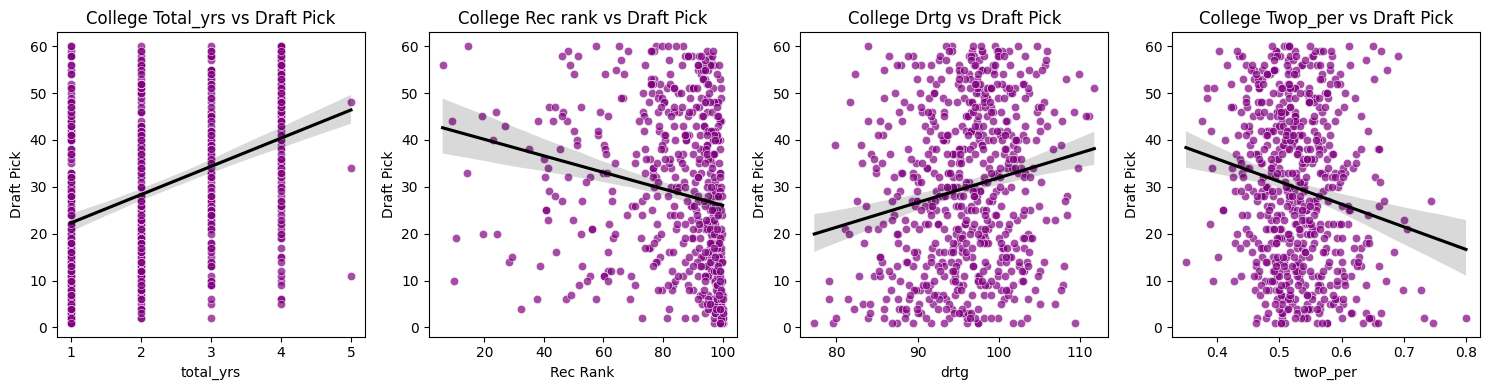

In [373]:
#
# 2. HYPOTHESIS 2: College Performance vs. Draft Position
#
# Selecting key performance statistics
perf_cols = ['pts', 'treb', 'oreb','dreb','ast', 'stl', 'blk', 'ast/tov','eFG','TS_per','Ortg', 'drtg','usg','FT_per','twoP_per','TP_per','Rec Rank','total_yrs']
for col in perf_cols:
    drafted_players[col] = pd.to_numeric(drafted_players[col], errors='coerce')

print("\n=== Correlation of College Performance with Draft Pick ===")
# Select the correlation specifically as a DataFrame with [['pick']] to keep it 2D for the heatmap
perf_corr_df = drafted_players[perf_cols + ['pick']].corr()[['pick']].drop('pick')
print(perf_corr_df['pick'])
print("\n")

plt.figure(figsize=(4, 10))
sns.heatmap(perf_corr_df, annot=True, cmap='coolwarm', fmt=".2f", cbar=True, vmin=-1, vmax=1)
plt.title('Correlation of Performance Metrics\nvs. Draft Pick Position')
plt.ylabel('Perf Metrics')
plt.show()

# Plotting top 3 performing factors
plt.figure(figsize=(15, 4))
for i, col in enumerate(perf_corr_df['pick'].abs().sort_values(ascending=False).head(4).index, 1):
    plt.subplot(1, 4, i)
    sns.scatterplot(data=drafted_players, x=col, y='pick', alpha=0.7, color='purple')
    sns.regplot(data=drafted_players, x=col, y='pick', scatter=False, color='black')
    plt.title(f'College {col.capitalize()} vs Draft Pick')
    plt.ylabel('Draft Pick')
plt.tight_layout()
plt.show()

In [374]:
# now t-test on binary drafted 1/0 groups, per performance metric:

# 1. Compare Physical Metrics: Drafted (1) vs. Undrafted (0) players
print("=== Average Physical Metrics by Draft Status (Drafted vs. Undrafted) ===")
group_drafted = data_df.groupby('drafted')[perf_cols].mean()
display(group_drafted)

# 2. T-tests for significance
print("\n=== 2. T-tests: Performance Metrics of Drafted vs. Undrafted ===")
for col in perf_cols:
    drafted_vals = data_df[data_df['drafted'] == 1][col].dropna()
    undrafted_vals = data_df[data_df['drafted'] == 0][col].dropna()
    if len(drafted_vals) > 1 and len(undrafted_vals) > 1:
        t_stat, p_val = stats.ttest_ind(drafted_vals, undrafted_vals, equal_var=False)
        print(f"{col:25} | T-stat: {t_stat:8.4f} | P-value: {p_val:.4e}")


# And a more granular check on draft categories via ANOVA:
print("\n=== 2. ANOVA: Performance Metrics by Draft Round ===")
for col in perf_cols:
    groups = [data_df[data_df['draft_round'] == r][col].dropna() for r in data_df['draft_round'].unique()]
    groups = [g for g in groups if len(g) > 0]
    if len(groups) > 1:
        f_stat, p_val = stats.f_oneway(*groups)
        print(f"{col:25} | F-stat: {f_stat:8.4f} | P-value: {p_val:.4e}")


=== Average Physical Metrics by Draft Status (Drafted vs. Undrafted) ===


,pts,treb,oreb,dreb,ast,stl,blk,ast/tov,eFG,TS_per,Ortg,drtg,usg,FT_per,twoP_per,TP_per,Rec Rank,total_yrs
drafted,,,,,,,,,,,,,,,,,,
0,5.656842,2.588090,0.731386,1.856706,1.042819,0.514796,0.260637,0.940463,42.953317,46.126762,89.138464,103.582540,18.024758,0.553375,0.410554,0.218370,51.063918,2.464698
1,15.353050,6.226692,1.682373,4.544319,2.546344,1.136266,0.905878,1.169823,54.158787,57.817201,112.755988,95.811482,24.572784,0.739673,0.529065,0.318011,84.336000,2.231726



=== 2. T-tests: Performance Metrics of Drafted vs. Undrafted ===
pts                       | T-stat:  58.8121 | P-value: 6.9733e-272
treb                      | T-stat:  38.5383 | P-value: 4.3931e-172
oreb                      | T-stat:  24.0289 | P-value: 3.7887e-92
dreb                      | T-stat:  42.0865 | P-value: 1.3074e-190
ast                       | T-stat:  22.1635 | P-value: 1.0489e-81
stl                       | T-stat:  30.3617 | P-value: 4.5684e-128
blk                       | T-stat:  19.6828 | P-value: 5.3442e-68
ast/tov                   | T-stat:   8.6381 | P-value: 3.9917e-17
eFG                       | T-stat:  45.8924 | P-value: 2.1653e-267
TS_per                    | T-stat:  53.4324 | P-value: 0.0000e+00
Ortg                      | T-stat:  60.5390 | P-value: 0.0000e+00
drtg                      | T-stat: -31.1674 | P-value: 1.4926e-139
usg                       | T-stat:  39.2625 | P-value: 2.0204e-182
FT_per                    | T-stat:  45.3752 | P-value: 

**3. College Experience vs. Upside (H3)**
- Research Question: Do younger players or prospects with fewer college seasons get prioritized in the draft?
- Hypothesis: Players entering the draft with fewer college seasons are drafted earlier, as teams value youth and upside over experience.


=== 3. ANOVA: College Experience (total_yrs) by Draft Round Category ===
Average College Years by Draft Round Group:
draft_round
Undrafted              2.464698
Round_2                2.619355
Non-Lottery_Round_1    2.098837
Lottery_Round_1        1.627329
Name: total_yrs, dtype: float64


One-way ANOVA Result for College Experience:
F-Statistic: 33.1587 | P-Value: 2.2074e-21


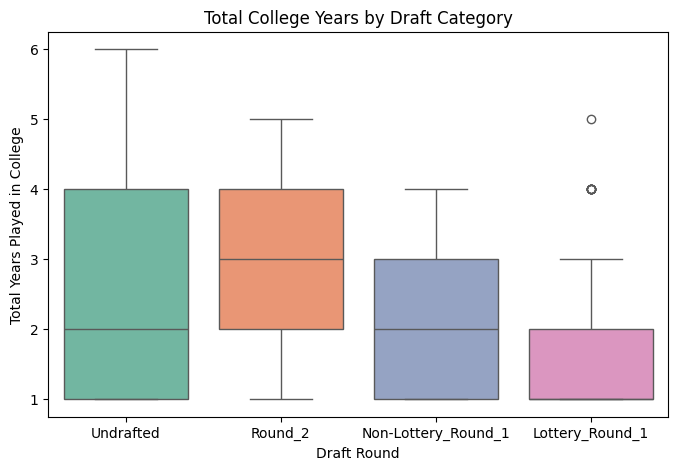

In [375]:
# --------------------------------------------------------
# 3. HYPOTHESIS 3: Experience (Years in College) vs. Draft
#
print("\n=== 3. ANOVA: College Experience (total_yrs) by Draft Round Category ===")

# Calculate average total years across draft round groups
avg_years_by_round = data_df.groupby('draft_round')['total_yrs'].mean()
print("Average College Years by Draft Round Group:")
print(avg_years_by_round)
print("\n")

# Prepare groups for ANOVA
groups_exp = [
    data_df[data_df['draft_round'] == r]['total_yrs'].dropna()
    for r in data_df['draft_round'].unique()
]

# Filter out empty groups
groups_exp = [g for g in groups_exp if len(g) > 0]

if len(groups_exp) > 1:
    f_stat, p_val = stats.f_oneway(*groups_exp)
    print(f"One-way ANOVA Result for College Experience:")
    print(f"F-Statistic: {f_stat:.4f} | P-Value: {p_val:.4e}")
else:
    print("Not enough data groups to perform ANOVA.")

# Plot distribution of college years by draft round category
plt.figure(figsize=(8, 5))
sns.boxplot(data=data_df, x='draft_round', y='total_yrs', palette='Set2', hue='draft_round', legend=False)
plt.title('Total College Years by Draft Category')
plt.xlabel('Draft Round')
plt.ylabel('Total Years Played in College')
plt.show()